<a href="https://colab.research.google.com/github/Joy-Kavata/traffic_prediction_model/blob/main/Traffic_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# Import core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb

# 1. Load your dataset (replace with your downloaded Kaggle CSV file name)
# df = pd.read_csv('your_traffic_data.csv')

# --- MOCK DATA EXAMPLE FOR TESTING THE PIPELINE ---
# (You can run this block immediately to verify the structure works)
date_rng = pd.date_range(start='2026-01-01', periods=1000, freq='H')
df = pd.DataFrame({
    'timestamp': date_rng,
    'speed': np.random.uniform(20, 60, size=(1000,)) # mock speeds in km/h
})
# --------------------------------------------------

# 2. Preprocessing: Set datetime index
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.set_index('timestamp', inplace=True)

# 3. Feature Engineering: Time features & Cyclical encoding (Assignment 2 specifications)
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# Cyclical encoding for hours (as planned in your design docs)
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24.0)

# 4. Feature Engineering: Lag features (Speed 1 hour ago)
df['speed_lag_1'] = df['speed'].shift(1)

# Drop rows with NaN values resulting from shifts
df.dropna(inplace=True)

print(df.head())

                         speed  hour  day_of_week  is_weekend  hour_sin  \
timestamp                                                                 
2026-01-01 01:00:00  30.751741     1            3           0  0.258819   
2026-01-01 02:00:00  38.148671     2            3           0  0.500000   
2026-01-01 03:00:00  28.584915     3            3           0  0.707107   
2026-01-01 04:00:00  43.709342     4            3           0  0.866025   
2026-01-01 05:00:00  32.681960     5            3           0  0.965926   

                     hour_cos  speed_lag_1  
timestamp                                   
2026-01-01 01:00:00  0.965926    53.980441  
2026-01-01 02:00:00  0.866025    30.751741  
2026-01-01 03:00:00  0.707107    38.148671  
2026-01-01 04:00:00  0.500000    28.584915  
2026-01-01 05:00:00  0.258819    43.709342  


/tmp/ipykernel_8154/2198015160.py:14: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_rng = pd.date_range(start='2026-01-01', periods=1000, freq='H')


In [8]:
import pandas as pd

# Load the uploaded CSV file into a DataFrame
# (Make sure to match the exact filename shown in your Colab files sidebar)
filename = 'Metro_Interstate_Traffic_Volume.csv'
df = pd.read_csv(filename)

# Verify it loaded correctly by checking the first 5 rows and column names
print(df.head())
print(df.columns)

  holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0     NaN  288.28      0.0      0.0          40       Clouds   
1     NaN  289.36      0.0      0.0          75       Clouds   
2     NaN  289.58      0.0      0.0          90       Clouds   
3     NaN  290.13      0.0      0.0          90       Clouds   
4     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description            date_time  traffic_volume  
0    scattered clouds  2012-10-02 09:00:00            5545  
1       broken clouds  2012-10-02 10:00:00            4516  
2     overcast clouds  2012-10-02 11:00:00            4767  
3     overcast clouds  2012-10-02 12:00:00            5026  
4       broken clouds  2012-10-02 13:00:00            4918  
Index(['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main',
       'weather_description', 'date_time', 'traffic_volume'],
      dtype='object')


In [9]:
# 1. Inspect the date/time column name from your previous printout
# (Usually 'date_time' in this specific dataset)
time_col = 'date_time'

# Convert the timestamp column to actual datetime objects and sort chronologically
df[time_col] = pd.to_datetime(df[time_col])
df = df.sort_values(by=time_col).reset_index(drop=True)

# Set the timestamp as the dataframe index
df.set_index(time_col, inplace=True)

# 2. Extract Temporal Features (Assignment 2 specification)
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# Cyclical encoding for hours (sine/cosine transformation)
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24.0)

# 3. Create Historical Lag Features (e.g., traffic volume 1 hour and 24 hours ago)
df['traffic_lag_1h'] = df['traffic_volume'].shift(1)
df['traffic_lag_24h'] = df['traffic_volume'].shift(24) # Same time yesterday

# 4. Rolling Window Statistics
df['rolling_mean_3h'] = df['traffic_volume'].rolling(window=3).mean()

# Drop missing values resulting from shifting and rolling windows
df.dropna(inplace=True)

print("Preprocessing and feature engineering complete!")
print(df[['traffic_volume', 'hour', 'is_weekend', 'traffic_lag_1h']].head())

Preprocessing and feature engineering complete!
            traffic_volume  hour  is_weekend  traffic_lag_1h
date_time                                                   
2012-10-08             455     0           0           959.0
2012-11-12            1000     0           0          2863.0
2012-11-22             919     0           0          1399.0
2012-12-25             803     0           0          1542.0
2013-01-01            1439     0           0          1596.0


In [10]:
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Define your features (X) and target variable (y)
features = ['hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'traffic_lag_1h', 'traffic_lag_24h', 'rolling_mean_3h']
target = 'traffic_volume'

X = df[features]
y = df[target]

# 2. Chronological Split (e.g., 80% for training, 20% for testing)
train_size = int(len(df) * 0.8)

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# 3. Train the XGBoost Baseline Regressor
model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)

# 4. Generate Predictions on the Test Set
predictions = model.predict(X_test)

# 5. Evaluate Performance using MAE and RMSE (Assignment 3 / CAT 1 metrics)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("\n--- Baseline Model Results ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Training set shape: (48, 9)
Testing set shape: (13, 9)

--- Baseline Model Results ---
Mean Absolute Error (MAE): 150.39
Root Mean Squared Error (RMSE): 190.63


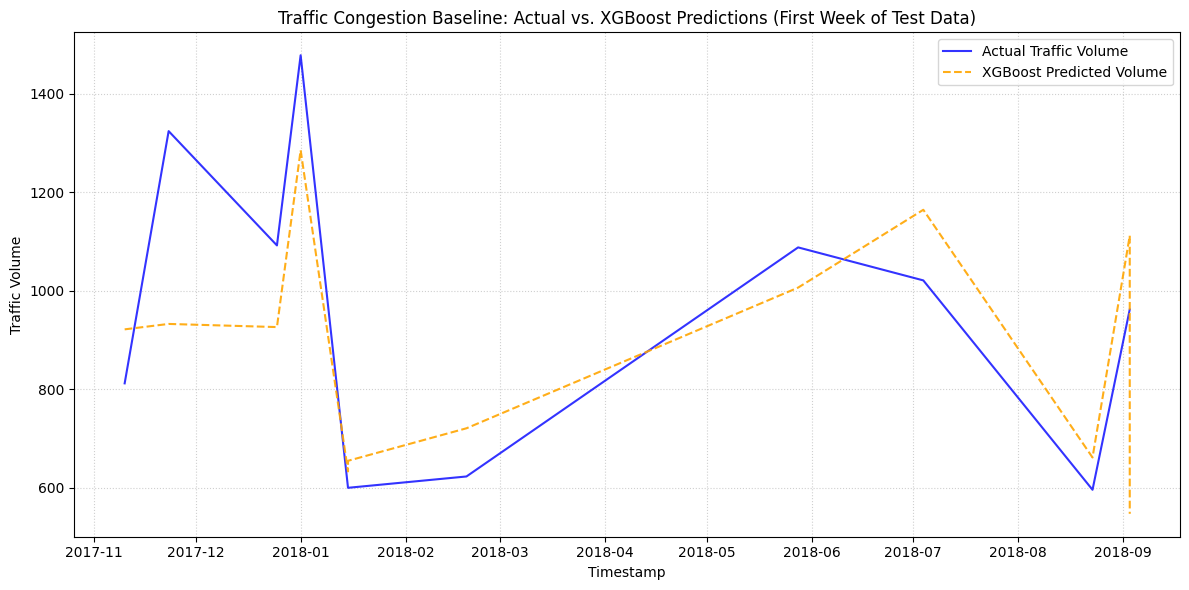

In [11]:
import matplotlib.pyplot as plt

# Plot a slice of actual vs predicted traffic volume (e.g., the first 168 hours / 1 week of the test set)
plt.figure(figsize=(12, 6))
plt.plot(y_test.index[:168], y_test.values[:168], label='Actual Traffic Volume', color='blue', alpha=0.8)
plt.plot(y_test.index[:168], predictions[:168], label='XGBoost Predicted Volume', color='orange', linestyle='--', alpha=0.9)

plt.title('Traffic Congestion Baseline: Actual vs. XGBoost Predictions (First Week of Test Data)')
plt.xlabel('Timestamp')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [12]:
import joblib

# Save the trained XGBoost model to a file
joblib.dump(model, 'traffic_xgboost_model.pkl')
print("Model saved successfully!")

Model saved successfully!


In [13]:
import joblib
from google.colab import files

# 1. Save your trained model to a file
joblib.dump(model, 'traffic_xgboost_model.pkl')

# 2. Automatically trigger the download to your computer
files.download('traffic_xgboost_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
%%writefile requirements.txt
streamlit
pandas
numpy
xgboost
scikit-learn

Writing requirements.txt


In [16]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Load your trained model
model = joblib.load('traffic_xgboost_model.pkl')

st.title("🚦 Traffic Congestion & Volume Predictor")
st.write("Predicting traffic volume based on temporal and weather features for your university project.")

# User inputs for the web interface
hour = st.slider("Select Hour of Day", 0, 23, 12)
day_of_week = st.selectbox("Day of Week (0=Monday, 6=Sunday)", [0, 1, 2, 3, 4, 5, 6])
is_weekend = 1 if day_of_week >= 5 else 0
month = st.slider("Select Month", 1, 12, 6)

# Cyclical encoding computation (matching your training pipeline)
hour_sin = np.sin(2 * np.pi * hour / 24.0)
hour_cos = np.cos(2 * np.pi * hour / 24.0)

# Input fields for historical features
traffic_lag_1h = st.number_input("Traffic Volume 1 Hour Ago", value=3000.0)
traffic_lag_24h = st.number_input("Traffic Volume Yesterday Same Time", value=3200.0)
rolling_mean_3h = st.number_input("3-Hour Rolling Mean Traffic", value=3100.0)

# Create input DataFrame for the model
input_data = pd.DataFrame([[
    hour, day_of_week, month, is_weekend, hour_sin, hour_cos,
    traffic_lag_1h, traffic_lag_24h, rolling_mean_3h
]], columns=[
    'hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos',
    'traffic_lag_1h', 'traffic_lag_24h', 'rolling_mean_3h'
])

# Prediction button
if st.button("Predict Traffic Volume"):
    prediction = model.predict(input_data)[0]
    st.success(f"Estimated Traffic Volume: **{int(prediction)} vehicles**")

    if prediction > 4500:
        st.error("Congestion Level: **HIGH** 🔴")
    elif prediction > 2500:
        st.warning("Congestion Level: **MEDIUM** 🟡")
    else:
        st.success("Congestion Level: **LOW** 🟢")

Writing app.py
